<a href="https://colab.research.google.com/github/Yanalzzz/-JoVision-AI-tasks/blob/main/Task4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
!git clone https://github.com/ultralytics/yolov5.git

%cd /content/yolov5

!pip install -r requirements.txt

Cloning into 'yolov5'...
remote: Enumerating objects: 18825, done.
remote: Counting objects: 100% (382/382), done.
remote: Compressing objects: 100% (231/231), done.
remote: Total 18825 (delta 314), reused 151 (delta 151), pack-reused 18443 (from 2)
Receiving objects: 100% (18825/18825), 17.73 MiB | 22.36 MiB/s, done.
Resolving deltas: 100% (12828/12828), done.
/content/yolov5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 11.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [2]:
from google.colab import drive
import zipfile
import os

# Mount Google Drive to the correct directory
drive.mount('/content/drive')

zip_path = '/content/Chess_dataset.zip'
extract_path = '/content/Chess_dataset'

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print(f'Extracted dataset to {extract_path}')
else:
    print(f'Zip file not found at {zip_path}')

Mounted at /content/drive
Extracted dataset to /content/Chess_dataset


In [3]:
classes = ['pawn','knight','bishop', 'rook','queen','king']

num_classes = len(classes)

print("Number of classes:", num_classes)
print("Classes:", classes)

Number of classes: 6
Classes: ['pawn', 'knight', 'bishop', 'rook', 'queen', 'king']


In [5]:
import yaml

data = {
    'path': '/content/Chess_dataset',
    'train': 'images/train',
    'val': 'images/val',
    'nc': 6,
    'names': classes
}

with open('/content/Chess_dataset/data.yaml', 'w') as file:
    yaml.dump(data, file, sort_keys=False)

print("data.yaml created successfully!")

data.yaml created successfully!


In [7]:
!python train.py \
    --img 640 \
    --batch 16 \
    --epochs 50 \
    --data /content/chess_dataset/data.yaml \
    --weights yolov5s.pt \
    --name chess_detection

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1793521806.664678    6341 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793521809.921030    6341 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 
wandb: WARNING W&B disabled due to login timeout.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights

In [8]:
!python detect.py \
    --weights runs/train/chess_detection/weights/best.pt \
    --source "$test_image" \
    --conf 0.25

detect: weights=['runs/train/chess_detection/weights/best.pt'], source=, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-561-gaf08ba15 Python-3.13.18 torch-2.11.0+cpu CPU

Traceback (most recent call last):
  File "/content/yolov5/detect.py", line 439, in <module>
    main(opt)
    ~~~~^^^^^
  File "/content/yolov5/detect.py", line 434, in main
    run(**vars(opt))
    ~~~^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/_contextlib.py", line 124, in decorate_context
    return func(*args, **kwargs)
  File "/content/yolov5/detect.py", line 172, in run
    model = DetectMultiBackend(weights, dev

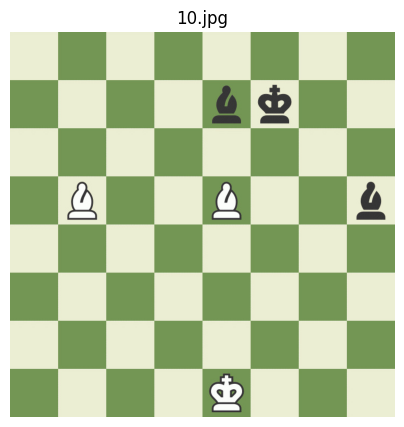

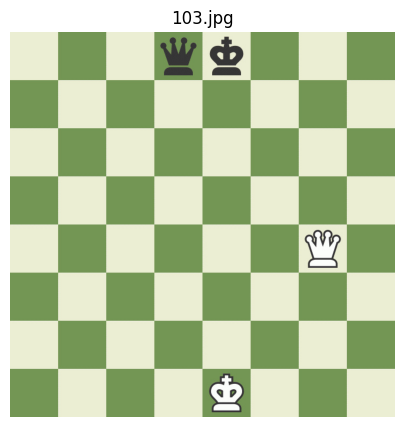

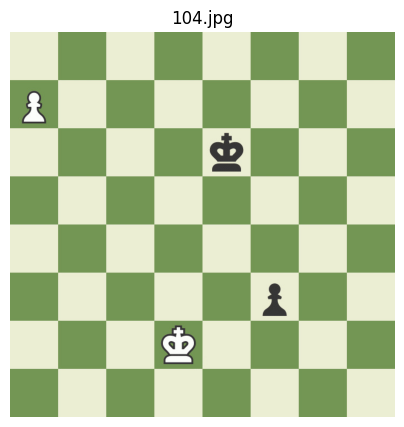

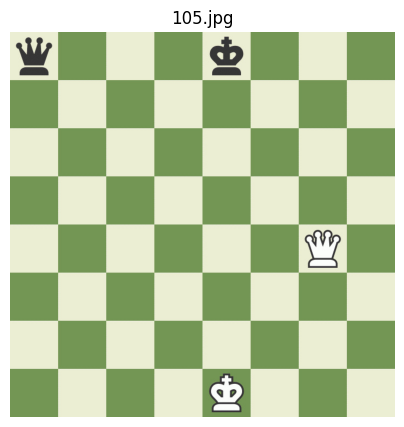

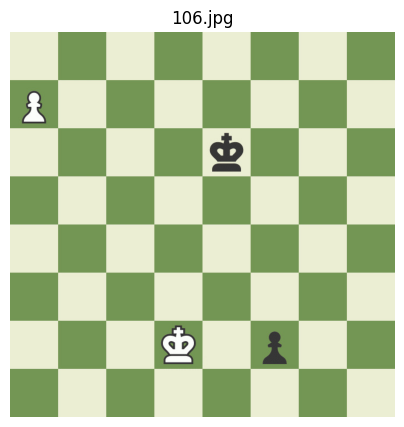

In [14]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import glob

dataset_path = '/content/Chess_dataset'
# Find images recursively in all subdirectories, case-insensitively
image_extensions = ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG')
images = []
for ext in image_extensions:
    images.extend(glob.glob(os.path.join(dataset_path, '**', ext), recursive=True))

images = sorted(images)

if not images:
    print(f"No images found in {dataset_path}. Here are the actual contents of the directory:")
    print(os.listdir(dataset_path))
else:
    for img_path in images[:5]:
        img = Image.open(img_path)
        plt.figure(figsize=(5, 5))
        plt.imshow(img)
        plt.title(os.path.basename(img_path))
        plt.axis('off')
        plt.show()